<a href="https://colab.research.google.com/github/jokuhrman/math289/blob/main/lecture2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Math 289: ML basics day 2

Training at scale, practical considerations, and attention.

Google Colab: **Run all** on menu bar. The first run downloads GPT-2 small (about 500 MB) for the attention demo in Section 3. No GPU is needed.

Current Notebook: [https://tinyurl.com/Math289MLLecture2](https://tinyurl.com/Math289MLLecture2)

Day 1 notebook: [ML basics day 1](https://colab.research.google.com/drive/1WclbqLCX_IO4UbA3S58TuVaah5wHJIoj?usp=sharing)

## Plan

| Time | Topic |
|---|---|
| 0–20 min | 1. Review of day 1 |
| 20–40 min | 2. Concrete numbers: parameters, data, cost, real training curves |
| 40–70 min | 3. Transformers and attention |
| 70–80 min | 4. Deep learning in mathematics |

In [ ]:
# Importing python "packages"
import base64
import io
import json
import math
import zlib
import numpy as np # Numerical calculations
import matplotlib.pyplot as plt # Plotting
from matplotlib.figure import Figure
import torch # Tensors, neural-network modules, automatic differentiation, optimizers
import ipywidgets as widgets
from IPython.display import display

In [ ]:
# @title
# Enable Colab's widget support; ordinary Jupyter needs no Colab-specific setup.
try:
    from google.colab import output
except ImportError:
    pass
else:
    output.enable_custom_widget_manager()

plt.rcParams.update({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Colors shared by all figures.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUE_RAMP = ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]


def figure_png(fig, dpi=110):
    # Widgets show figures as PNG images, which works the same in Colab and Jupyter.
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=dpi, bbox_inches="tight", facecolor="white")
    return buffer.getvalue()


def quiet_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)

## 1. Review of day 1

### Hyperparameters

Choices made before training starts.

- **Number of parameters**: the width and depth of the network.
- **Optimizer**: gradient descent, SGD, Adam, variants
- **Learning rate** $\eta$ (how big are gradient updates).
- **Batch size**: how many examples go into each gradient step
- **Architecture**: how different components of the network fit together


### MLP structure

$$f_\theta(x) = W_L\,\sigma\big(W_{L-1}\,\sigma(\cdots\sigma(W_1 x + b_1)\cdots) + b_{L-1}\big) + b_L, \qquad \theta = (W_1, b_1, \dots, W_L, b_L)$$


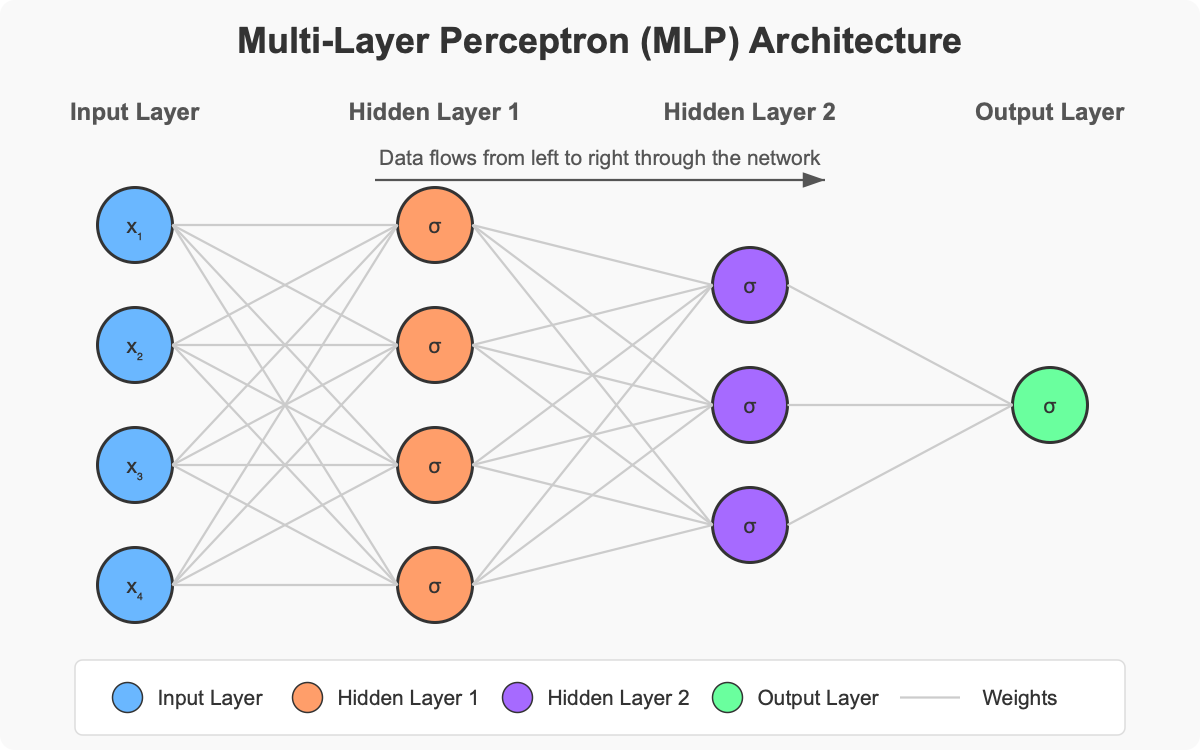





### Training loop

0. Initialize the model (with random weights or from another model)
1. Data with labels: $(x_i, y_i)$.
2. Forward pass of the model: $\hat y_i = f_\theta(x_i)$.
3. Compute the loss and its gradient from the model output and the label: $L(\theta) = \frac{1}{B}\sum_{i=1}^{B} \ell(\hat y_i, y_i)$ and $g = \nabla_\theta L$. $g$ is computed with respect to each parameter via autograd (as Otis covered) "backward pass"
4. Update the weights: $\theta \leftarrow \theta - \eta\, g$, or the optimizer's version of this step.

### Weirdness of deep learning

Deep learning is very much an experimental science.

1. Classical picture: the bias/variance tradeoff
- Actual picture: double descent
- Grokking: test accuracy jumps long after the training loss is near zero.

2. Classical optimization intuition does not translate to effectiveness
- Adam does not converge on general convex functions

3. Still somewhat predictable, but no theory exists
- Scaling laws (how to trade off data vs model size)





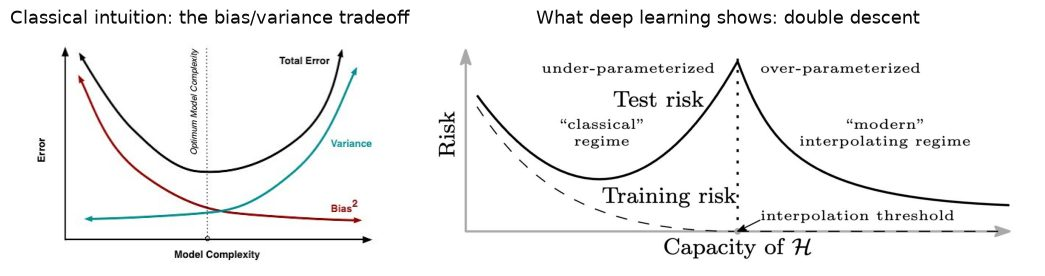

Left: the classical picture. Right: the double descent curve of [Belkin, Hsu, Ma, Mandal, *Reconciling modern machine learning practice and the bias-variance trade-off*](https://arxiv.org/abs/1812.11118).

### Data

- Data is extremely important (There will be a separate lecture on data only)
- Data should be the first thing you consider when thinking of doing deep learning
- Different stages of training use different kinds of data (generally, more high quality data towards the end of training)
- Deep learning is very data hungry
- Data can be found on HuggingFace (or ask ChatGPT/Claude to find a dataset)

## 2. Concrete numbers


<details>
<summary>Published numbers (click to open)</summary>
<table>
<tr><th>Model</th><th>Year</th><th>Parameters N</th><th>Layers</th><th>MLP hidden width</th><th>Training data D</th><th>Source</th></tr>
<tr><td>GPT-2</td><td>2019</td><td>124M to 1.5B</td><td>12 to 48</td><td>3,072 to 6,400</td><td>40 GB of text</td><td><a href="https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf">Radford et al.</a>, <a href="https://github.com/openai/gpt-2">released models</a></td></tr>
<tr><td>GPT-3</td><td>2020</td><td>175B</td><td>96</td><td>49,152</td><td>300B tokens</td><td><a href="https://arxiv.org/abs/2005.14165">Brown et al.</a></td></tr>
<tr><td>Llama 2 70B</td><td>2023</td><td>70B</td><td>80</td><td>28,672</td><td>2T tokens</td><td><a href="https://arxiv.org/abs/2307.09288">Touvron et al.</a>, <a href="https://huggingface.co/NousResearch/Llama-2-70b-hf/blob/main/config.json">config</a></td></tr>
<tr><td>Llama 3.1 405B</td><td>2024</td><td>405B</td><td>126</td><td>53,248</td><td>over 15T tokens, on over 16,000 H100 GPUs</td><td><a href="https://ai.meta.com/blog/meta-llama-3-1/">Meta</a>, <a href="https://arxiv.org/abs/2407.21783">Llama 3 paper</a></td></tr>
<tr><td>DeepSeek-V3</td><td>2024</td><td>671B (37B active per token)</td><td>61</td><td>2,048 per expert</td><td>14.8T tokens, 2.788M H800 GPU-hours</td><td><a href="https://arxiv.org/abs/2412.19437">DeepSeek-AI</a>, <a href="https://huggingface.co/deepseek-ai/DeepSeek-V3/blob/main/config.json">config</a></td></tr>
</table>
</details>

### Estimating cost

For a model with $N$ parameters trained on $D$ data points:

$$\text{forward pass} \approx 2ND \text{ FLOPs}, \qquad \text{backward pass} \approx 4ND \text{ FLOPs}, \qquad \text{total} \approx 6ND$$

H100 FLOPS per sec $\approx 495 * 10^{12}$

H100 cost per hour ~$3

Training a 128M parameter model on 1B datapoints costs around $1.29 in <30 min




### Curves from actual training runs

Public runs from [Wen, Hall, Ma, Liang, *Fantastic Pretraining Optimizers and Where to Find Them*](https://arxiv.org/abs/2509.02046).

All 4,858 runs are on [Weights & Biases](https://wandb.ai/marin-community/optimizer-scaling). The models are Llama-style transformers with 32 layers and sequence length 4,096.

- **Optimizers**: a 1.2B-parameter model trained on 96B tokens with AdamW and Muon.

In [ ]:
#@title Load the recorded runs (run once)
# This compressed payload holds loss, learning rate, and parameter and gradient norms
# sampled from 2 of the public runs. No external files or downloads are needed for replay.
_training_runs_payload = '...'
training_runs = json.loads(zlib.decompress(base64.b64decode(_training_runs_payload)))
del _training_runs_payload
print(len(training_runs["runs"]), "runs loaded from", training_runs["source"])

2 runs loaded from https://wandb.ai/marin-community/optimizer-scaling


In [ ]:
#@title Training curves helper (run once)
NORM_PARTS = [
    ("All parameters", "total"),
    ("Attention matrices (Q, K, V, O)", "attn"),
    ("MLP matrices", "mlp"),
    ("Token embedding", "embed"),
    ("Output layer", "head"),
]
OPTIMIZER_COLORS = {"adamw": BLUE, "muon": ORANGE}


class TrainingCurvesDemo:
    def __init__(self, recording):
        self.runs = recording["runs"]
        style = {"description_width": "110px"}
        narrow = widgets.Layout(width="330px", max_width="100%")
        self.part = widgets.Dropdown(description="Norm of", options=NORM_PARTS, value="total",
                                     style=style, layout=narrow)
        self.window = widgets.Dropdown(
            description="Steps shown",
            options=[("Whole run", 0.0), ("Second half", 0.5), ("Last 20%", 0.8)],
            value=0.0, style=style, layout=narrow)
        self.log_steps = widgets.Checkbox(description="Log step axis", value=False, indent=False,
                                          layout=widgets.Layout(width="160px"))
        self.optimizer_boxes = {
            run["key"]: widgets.Checkbox(description=run["label"], value=True, indent=False,
                                         layout=widgets.Layout(width="190px"))
            for run in self.runs}
        row = widgets.Layout(display="flex", flex_flow="row wrap", align_items="center", width="100%")
        self.image = widgets.Image(format="png",
                                   layout=widgets.Layout(width="100%", max_width="1150px"))
        self.note = widgets.HTML()
        self.ui = widgets.VBox([
            widgets.HBox(list(self.optimizer_boxes.values()), layout=row),
            widgets.HBox([self.part, self.window, self.log_steps], layout=row),
            self.image, self.note,
        ], layout=widgets.Layout(width="100%"))
        controls = [self.part, self.window, self.log_steps] + list(self.optimizer_boxes.values())
        for control in controls:
            control.observe(self.render, names="value")
        self.render()

    def selected(self):
        return [(run, OPTIMIZER_COLORS[run["key"]]) for run in self.runs
                if self.optimizer_boxes[run["key"]].value]

    def render(self, change=None):
        chosen = self.selected()
        fig = Figure(figsize=(12.5, 7.6))
        axes = fig.subplots(2, 2)
        loss_ax, rate_ax, norm_ax, grad_ax = axes.ravel()
        part = self.part.value
        part_name = {key: name for name, key in NORM_PARTS}[part].replace("All", "all")
        loss_low, loss_high = [], []
        first_step, last_step = 1, 1
        for run, color in chosen:
            last_step = run["steps"]
            first_step = max(self.window.value * last_step, 10 if self.log_steps.value else 0)
            train_steps, train_loss = np.array(run["train"])
            eval_steps, eval_loss = np.array(run["eval"])
            loss_ax.plot(train_steps, train_loss, color=color, linewidth=0.8, alpha=0.35)
            loss_ax.plot(eval_steps, eval_loss, color=color, linewidth=2, label=run["label"])
            shown_train = train_loss[train_steps >= first_step]
            shown_eval = eval_loss[eval_steps >= first_step]
            if len(shown_eval):
                loss_low.append(shown_eval.min())
                if self.log_steps.value or self.window.value > 0:
                    loss_high.append(shown_eval.max())
            if len(shown_train):
                loss_low.append(shown_train.min())
                # On a linear step axis the first steps would flatten the rest of the curve.
                loss_high.append(np.percentile(shown_train, 99) if self.log_steps.value
                                 else 1.5 * np.median(shown_train))
            rate_ax.plot(*run["lr_curve"], color=color, linewidth=2)
            norm_ax.plot(run["norm"]["steps"], run["norm"][part], color=color, linewidth=2)
            grad_ax.plot(run["grad"]["steps"], run["grad"][part], color=color, linewidth=2)
        if loss_low:
            pad = 0.05 * (max(loss_high) - min(loss_low) + 1e-9)
            loss_ax.set_ylim(min(loss_low) - pad, max(loss_high) + pad)
        loss_ax.set_title("Loss (thin: training batches, thick: evaluation)", color=INK, fontsize=12)
        if not self.log_steps.value and self.window.value == 0:
            loss_ax.set_title("Loss (thin: training batches, thick: evaluation), first steps cut off",
                              color=INK, fontsize=12)
        rate_ax.set_title("Learning rate", color=INK, fontsize=12)
        norm_ax.set_title(f"Parameter norm: {part_name}", color=INK, fontsize=12)
        grad_ax.set_title(f"Gradient norm (log axis): {part_name}", color=INK, fontsize=12)
        for ax in axes.ravel():
            quiet_axes(ax)
            if self.log_steps.value:
                ax.set_xscale("log")
            if chosen:
                ax.set_xlim(first_step, last_step)
            ax.xaxis.set_major_formatter(lambda value, _: f"{value / 1000:g}k" if value >= 1000 else f"{value:g}")
        # The other panels autoscale to the visible window.
        grad_ax.set_yscale("log")
        for ax in (rate_ax, norm_ax, grad_ax):
            visible = [np.array(line.get_ydata())[np.array(line.get_xdata()) >= first_step]
                       for line in ax.get_lines()]
            visible = [values for values in visible if len(values)]
            if visible and ax is grad_ax:
                ax.set_ylim(0.8 * min(v.min() for v in visible), 1.25 * max(v.max() for v in visible))
            elif visible:
                low, high = min(v.min() for v in visible), max(v.max() for v in visible)
                pad = 0.06 * (high - low + 1e-12)
                ax.set_ylim(max(0, low - pad), high + pad)
        for ax in (norm_ax, grad_ax):
            ax.set_xlabel("Training step", color=MUTED)
        if chosen:
            handles, labels = loss_ax.get_legend_handles_labels()
            fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False,
                       bbox_to_anchor=(0.5, 0.98))
        fig.subplots_adjust(hspace=0.32, wspace=0.2)
        self.image.value = figure_png(fig)

        cell = "padding:3px 14px 3px 0"
        head = "".join(f"<th style='{cell};text-align:left'>{name}</th>" for name in
                       ("", "Run", "Learning rate", "Weight decay", "Schedule", "Final evaluation loss", ""))
        body = "".join(
            f"<tr><td style='{cell}'><span style='display:inline-block;width:14px;height:14px;"
            f"border-radius:3px;background:{color}'></span></td>"
            f"<td style='{cell}'>{run['label']}</td><td style='{cell}'>{run['lr']:g}</td>"
            f"<td style='{cell}'>{run['weight_decay']:g}</td><td style='{cell}'>{run['schedule']}</td>"
            f"<td style='{cell}'>{run['final_eval_loss']:.4f}</td>"
            f"<td style='{cell}'><a href='{run['url']}' target='_blank'>W&amp;B run</a></td></tr>"
            for run, color in chosen)
        tokens = f"{chosen[0][0]['tokens_per_step']:,}" if chosen else "–"
        self.note.value = (f"<table style='margin:6px 0'><tr>{head}</tr>{body}</table>"
                           f"<span style='color:{MUTED}'>One step is {tokens} tokens. "
                           "Norms are the l2 norms.</span>")

In [ ]:
#@title Start the training curves demo (run once)
curves_demo = TrainingCurvesDemo(training_runs)
display(curves_demo.ui)

1.2B Parameter models trained on 96B tokens. Task is next-token prediction. (Exercise: compute how much this costs)

Things to look for:

- **Noisy training curves, smooth evaluation curves**
- **Learning rate scheduling**
- **Parameter norms grow**
- **Smaller weights, larger gradients**



### Optimizers used

AdamW and Muon are used much more than plain gradient descent or SGD.

- **AdamW**: momentum, a separate step size for each coordinate from a running average of squared gradients, and decoupled weight decay. [Loshchilov and Hutter](https://arxiv.org/abs/1711.05101)
- **Muon**: for each weight matrix, take the momentum $M = U\Sigma V^\top$ and step along $UV^\top$, with every singular value set to 1. [Jordan's post](https://kellerjordan.github.io/posts/muon/)

## 3. Transformers and attention

**Attention** is how the model combines information from different positions in the data.

The "units" of data in attention are called **tokens**.


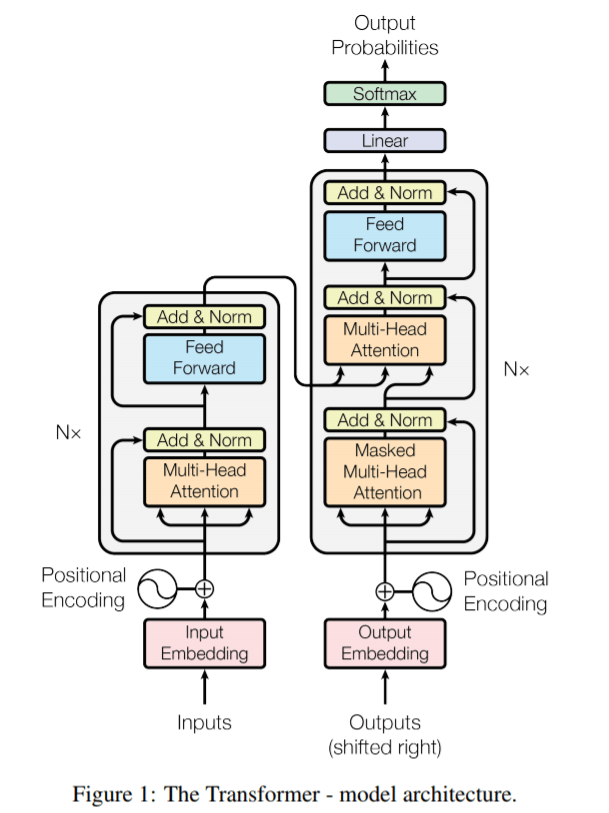


### Where the parameters are

GPT-2 Large: 63% of parameters in MLP, 32% in Attention

LLama 3.1 405B: 81% in MLP, 18% in Attention

Deepseek-V3: 98% MLP, 2% Attention


In [ ]:
#@title Load GPT-2 small (run once; downloads about 500 MB the first time)
from transformers import AutoModelForCausalLM, AutoTokenizer

gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
try:
    # Attention weights are only returned by the plain ("eager") attention code.
    gpt2 = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager")
except (TypeError, ValueError):
    gpt2 = AutoModelForCausalLM.from_pretrained("gpt2")
gpt2.eval()
print(f"GPT-2 small: {sum(p.numel() for p in gpt2.parameters()):,} parameters")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 small: 124,439,808 parameters


In [ ]:
#@title Count the parameters by part (run once)
def parameter_split(model):
    counts = {"MLP": 0, "Token embedding": 0, "Attention": 0, "Position embedding": 0, "Norms": 0}
    for name, parameter in model.named_parameters():
        if ".attn." in name:
            counts["Attention"] += parameter.numel()
        elif ".mlp." in name:
            counts["MLP"] += parameter.numel()
        elif "wte" in name:
            counts["Token embedding"] += parameter.numel()
        elif "wpe" in name:
            counts["Position embedding"] += parameter.numel()
        else:
            counts["Norms"] += parameter.numel()
    return counts


def plot_parameter_split(model):
    counts = parameter_split(model)
    total = sum(counts.values())
    names = sorted(counts, key=counts.get)
    fig, ax = plt.subplots(figsize=(8.5, 2.8))
    ax.barh(names, [counts[name] / 1e6 for name in names], height=0.62,
            color=[ORANGE if name == "Attention" else BLUE if name == "MLP" else "#c3c2b7"
                   for name in names])
    for index, name in enumerate(names):
        ax.text(counts[name] / 1e6 + 0.8, index,
                f"{counts[name] / 1e6:.1f}M  ({100 * counts[name] / total:.0f}%)",
                va="center", color=INK, fontsize=10)
    ax.set_xlim(0, 1.3 * max(counts.values()) / 1e6)
    ax.set_xlabel("Parameters (millions)", color=MUTED)
    ax.set_title(f"GPT-2 small: {total / 1e6:.1f}M parameters", color=INK, fontsize=12)
    ax.tick_params(colors=MUTED)
    ax.tick_params(axis="y", colors=INK, length=0)
    ax.grid(axis="x", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    plt.show()

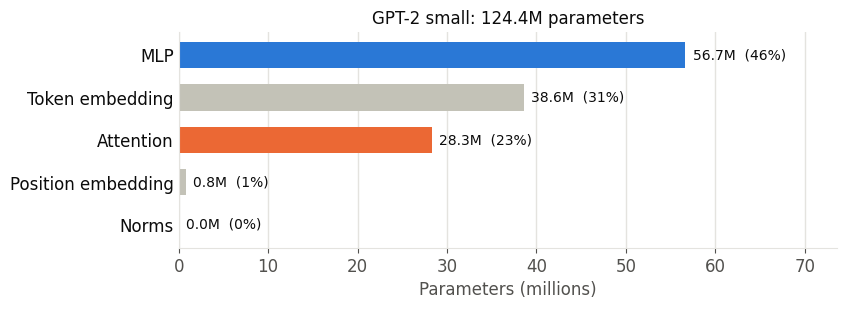

In [ ]:
plot_parameter_split(gpt2)

### Attention is not only for language

Attention applies to anything with relationships between the elements of a sequence.

- Protein structure: [AlphaFold](https://www.nature.com/articles/s41586-021-03819-2)
- Images and video: [Vision Transformer](https://arxiv.org/abs/2010.11929), [ViViT](https://arxiv.org/abs/2103.15691)
- Robotics: [RT-1](https://arxiv.org/abs/2212.06817)
- PDEs: [Transformer for PDE operator learning](https://arxiv.org/abs/2205.13671)
- Time series prediction: [Informer](https://arxiv.org/abs/2012.07436)
- Audio: [Whisper](https://arxiv.org/abs/2212.04356)

### How tokens are related to each other

GPT-2 small has 12 layers with 12 attention heads each.
Each head produces weights over that token and the tokens before it.

Row: the token doing the looking. Column: the token being looked at.

In [ ]:
# The computation, independent of the controls.
MAX_ATTENTION_TOKENS = 32


@torch.no_grad()
def gpt2_attention(text):
    # GPT-2 text starts with a special start token. Many heads put most of their weight on it.
    ids = [gpt2_tokenizer.bos_token_id] + gpt2_tokenizer.encode(text)[:MAX_ATTENTION_TOKENS]
    result = gpt2(torch.tensor([ids]), output_attentions=True)
    weights = torch.stack(result.attentions)[:, 0].numpy()    # layers x heads x tokens x tokens
    tokens = ["<start>"] + [gpt2_tokenizer.decode([i]) for i in ids[1:]]
    return tokens, weights

In [ ]:
#@title Attention heatmap helper (run once)
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

ATTENTION_CMAP = LinearSegmentedColormap.from_list("attention", BLUE_RAMP)
ATTENTION_CMAP.set_bad("#f0efec")
CAT_TEXT = "The cat sat on the mat because it was tired."
REPEATED_TEXT = "The quick brown fox jumps over the lazy dog. The quick brown fox jumps over"
ATTENTION_PRESETS = [
    # label, layer, head, text, token to select (None selects the last token)
    ("Layer 5, head 12: every token looks at the previous token", 5, 12, CAT_TEXT, None),
    ("Layer 5, head 4: 'it' looks at 'cat'", 5, 4, CAT_TEXT, " it"),
    ("Layer 6, head 6: in repeated text, look at what came next last time", 6, 6, REPEATED_TEXT, None),
]


class AttentionDemo:
    def __init__(self):
        style = {"description_width": "70px"}
        slider = widgets.Layout(width="330px", max_width="100%")
        self.preset = widgets.Dropdown(
            description="Preset", options=[(p[0], i) for i, p in enumerate(ATTENTION_PRESETS)],
            value=1, style=style, layout=widgets.Layout(width="640px", max_width="100%"))
        self.text = widgets.Text(description="Text", value=CAT_TEXT, continuous_update=False,
                                 style=style, layout=widgets.Layout(width="100%", max_width="900px"))
        self.layer = widgets.IntSlider(description="Layer", value=5, min=1, max=12,
                                       continuous_update=False, style=style, layout=slider)
        self.head = widgets.IntSlider(description="Head", value=4, min=1, max=12,
                                      continuous_update=False, style=style, layout=slider)
        self.average = widgets.Checkbox(description="Average over the 12 heads", value=False,
                                        indent=False, layout=widgets.Layout(width="230px"))
        self.token = widgets.Dropdown(description="Token", style=style,
                                      layout=widgets.Layout(width="250px", max_width="100%"))
        self.show_start = widgets.Checkbox(description="Show the start token", value=False,
                                           indent=False, layout=widgets.Layout(width="200px"))
        self.image = widgets.Image(format="png",
                                   layout=widgets.Layout(width="100%", max_width="1150px"))
        self.note = widgets.HTML()
        row = widgets.Layout(display="flex", flex_flow="row wrap", align_items="center", width="100%")
        self.ui = widgets.VBox([
            self.preset, self.text,
            widgets.HBox([self.layer, self.head, self.average], layout=row),
            widgets.HBox([self.token, self.show_start], layout=row),
            self.image, self.note,
        ], layout=widgets.Layout(width="100%"))
        self.updating = False
        self.preset.observe(self.apply_preset, names="value")
        self.text.observe(self.read_text, names="value")
        for control in (self.layer, self.head, self.average, self.token, self.show_start):
            control.observe(self.render, names="value")
        self.apply_preset()

    def apply_preset(self, change=None):
        _, layer, head, text, token = ATTENTION_PRESETS[self.preset.value]
        self.updating = True
        self.layer.value, self.head.value, self.average.value = layer, head, False
        self.text.value = text
        self.updating = False
        self.read_text(select=token)

    def read_text(self, change=None, select=None):
        if self.updating:
            return
        self.tokens, self.weights = gpt2_attention(self.text.value)
        self.labels = [token.strip() or "␣" for token in self.tokens]
        chosen = len(self.tokens) - 1
        if select in self.tokens:
            chosen = self.tokens.index(select)
        self.updating = True
        self.token.options = [(f"{index}. {label}", index)
                              for index, label in enumerate(self.labels) if index > 0] or [("–", 0)]
        self.token.value = chosen
        self.updating = False
        self.render()

    def render(self, change=None):
        if self.updating:
            return
        layer, head = self.layer.value, self.head.value
        self.head.disabled = self.average.value
        weights = self.weights[layer - 1]
        weights = weights.mean(axis=0) if self.average.value else weights[head - 1]
        first = 0 if self.show_start.value else 1
        labels = self.labels[first:]
        count = len(labels)
        if count == 0:
            self.note.value = "Type some text."
            return
        shown = weights[first:, first:]
        focus = max(self.token.value, first) - first

        fig = Figure(figsize=(12.5, max(4.6, 0.33 * count + 2.2)))
        grid = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.4)
        heat_ax, bar_ax = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])
        future = np.triu(np.ones_like(shown, dtype=bool), k=1)
        picture = heat_ax.imshow(np.ma.masked_where(future, shown), cmap=ATTENTION_CMAP, vmin=0, vmax=1)
        heat_ax.set_xticks(range(count), labels, rotation=90)
        heat_ax.set_yticks(range(count), labels)
        heat_ax.set_xticks(np.arange(-0.5, count), minor=True)
        heat_ax.set_yticks(np.arange(-0.5, count), minor=True)
        heat_ax.grid(which="minor", color="white", linewidth=1.5)
        heat_ax.tick_params(which="both", length=0, colors=INK)
        for side in heat_ax.spines.values():
            side.set_visible(False)
        heat_ax.add_patch(Rectangle((-0.5, focus - 0.5), count, 1, fill=False,
                                    edgecolor=ORANGE, linewidth=2.5, zorder=5))
        heat_ax.set_xlabel("Token being looked at", color=MUTED)
        heat_ax.set_ylabel("Token doing the looking", color=MUTED)
        which = f"layer {layer}, average of 12 heads" if self.average.value else f"layer {layer}, head {head}"
        heat_ax.set_title(f"Attention weights: {which}", color=INK, fontsize=12)
        bar = fig.colorbar(picture, ax=heat_ax, fraction=0.046, pad=0.03)
        bar.outline.set_visible(False)
        bar.ax.tick_params(colors=MUTED, length=0)

        row = shown[focus, : focus + 1]
        bar_ax.barh(range(len(row)), row, height=0.62, color=BLUE)
        for index in np.argsort(-row)[:3]:
            bar_ax.text(row[index] + 0.02, index, f"{row[index]:.2f}", va="center", color=INK, fontsize=10)
        bar_ax.set_yticks(range(len(row)), labels[: focus + 1])
        bar_ax.invert_yaxis()
        bar_ax.set_xlim(0, 1.12)
        bar_ax.set_xlabel("Attention weight", color=MUTED)
        bar_ax.set_title(f"Where “{labels[focus]}” looks", color=INK, fontsize=12)
        bar_ax.tick_params(colors=MUTED)
        bar_ax.tick_params(axis="y", colors=INK, length=0)
        bar_ax.grid(axis="x", color=GRID, linewidth=1)
        bar_ax.set_axisbelow(True)
        for side in ("left", "bottom"):
            bar_ax.spines[side].set_color(GRID)
        self.image.value = figure_png(fig)

        notes = []
        if not self.show_start.value:
            notes.append(f"“{labels[focus]}” puts {weights[focus + 1, 0]:.2f} of its weight on the "
                         "hidden start token.")
        if len(gpt2_tokenizer.encode(self.text.value)) > MAX_ATTENTION_TOKENS:
            notes.append(f"Only the first {MAX_ATTENTION_TOKENS} tokens are shown.")
        notes.append("Gray cells are later tokens, which a token cannot look at.")
        self.note.value = f"<span style='color:{MUTED}'>{' '.join(notes)}</span>"

In [ ]:
#@title Start the attention heatmap (run once)
attention_demo = AttentionDemo()
display(attention_demo.ui)

### The attention mechanism

Input: $X \in \mathbb{R}^{n \times d}$, one row per token. Three learned matrices $W_Q$, $W_K$, $W_V$.

$$Q = XW_Q, \qquad K = XW_K, \qquad V = XW_V$$

$$A = \operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + M\Big), \qquad \text{output} = AV$$

| Matrix | Heuristic |
|---|---|
| Query $Q$ | What this token is looking for. |
| Key $K$ | What this token offers to other tokens. |
| Value $V$ | What this token passes on if it is looked at. |

$A_{ij}$ is how much token $i$ looks at token $j$. Each row of $A$ sums to 1. The mask $M$ is $-\infty$ where $j > i$ and $0$ elsewhere, so a token cannot look at later tokens.

Reference: [Vaswani et al., *Attention Is All You Need*](https://arxiv.org/abs/1706.03762).

### Attention Training Loop

1. Data: Tokenize text into $t_1, \dots, t_n, t_{n+1}$. Use $t_{n+1}$ as the label for the data $t_1, \dots, t_n$
2. Embed tokens into vectors, stack $t_1, \dots, t_n$ into $X \in \mathbb{R}^{n \times d}$
3. Compute the Query matrix $Q$, Key matrix $K$, and Value matrix $V$, using $W_Q, W_K, W_V$.
4. Compute $QK^T$ -- How much information should token $i$ take from token $j$?
5. Normalize and mask (prevent tokens from seeing into future), softmax to get Attention matrix $A$
6. Compute $AV$ -- weighted sum of the values of each token, with weights given by the Attention matrix $A$.
7. Use this to generate $t^{'}_{n+1}$ (next time)
8. Compute loss by comparing to $t_{n+1}$, compute gradients, backpropogate to update $W_Q, W_K, W_V$.

### Multi-head attention

Split each token (which is in $\mathbb{R}^d$) into $h$ vectors, each in $\mathbb{R}^{k}$ where $k = d/h$. Then do the same as above with adjusted dimensions. Concatenate the $h$ vectors, each in $\mathbb{R}^k,$ at the end and then multiply by an output matrix.


## 4. Deep learning in mathematics

### Guiding intuition: knots and representation theory

[Davies et al., *Advancing mathematics by guiding human intuition with AI*](https://www.nature.com/articles/s41586-021-04086-x), Nature 2021.

- Train a network to predict a mathematical quantity from some other mathematical data
- Attribution shows which inputs the network uses. Mathematicians turn that into a conjecture and prove it.
- Results: a new connection between the algebraic and geometric structure of knots (the signature and hyperbolic invariants), and a candidate algorithm predicted by the combinatorial invariance conjecture for symmetric groups.

<img src="https://media.springernature.com/lw1200/springer-static/image/art%3A10.1038%2Fs41586-021-04086-x/MediaObjects/41586_2021_4086_Fig1_HTML.png" width="820">

Figure 1 of the paper (CC BY 4.0).

### Finding counterexamples: graph theory

[Wagner, *Constructions in combinatorics via neural networks*](https://arxiv.org/abs/2104.14516), 2021.

- A network builds a graph one edge at a time. The reward is how close the graph comes to violating a conjecture.
- Training uses reinforcement learning (the deep cross-entropy method). No data about known graphs is needed.
- Result: explicit counterexamples to several conjectures. One is a graph on 19 vertices with $\lambda_1 + \mu < \sqrt{n-1} + 1$, where $\lambda_1$ is the largest eigenvalue and $\mu$ is the matching number.

<img src="https://arxiv.org/html/2104.14516v1/scores.png" width="430">

Figure 2 of the paper. The best constructions cross the conjectured bound after about 5,000 iterations.

### Searching for ribbons: knot theory

[Gukov, Halverson, Manolescu, Ruehle, *Searching for ribbons with machine learning*](https://arxiv.org/abs/2304.09304), 2023.

- Question: when does a knot bound a ribbon disk?
- Bayesian optimization and reinforcement learning search for sequences of band moves that show a knot is ribbon.
- Results: many ribbon knots detected in the range of up to 70 crossings, and many potential counterexamples to the smooth 4-dimensional Poincaré conjecture ruled out.

<img src="https://arxiv.org/html/2304.09304v2/BandExample.png" width="900">

Figure 5 of the paper: adding a band to the trefoil, and the corresponding dual graph.